# Спрос на платное ТВ: логит, вложенный логит, BLP и симуляция слияния

**Задача.** По агрегированным данным о ценах и долях рынка оценить спрос на четыре пакета платного ТВ (два спутниковых и два кабельных), восстановить издержки и наценки операторов и ответить на два вопроса, типичных для антимонопольного анализа и ценообразования:
1. что будет с ценами и потребителями, если два спутниковых оператора сольются;
2. у кого новый спутниковый пакет будет забирать клиентов.

**Что сделано**
- Оценены три модели дискретного выбора: мультиномиальный логит, вложенный логит (гнёзда «спутник» и «кабель») и логит со случайными коэффициентами (BLP). Цена эндогенна, поэтому везде используются инструменты; для сравнения показано смещение OLS.
- Для всех моделей посчитаны эластичности и diversion ratios.
- Из условий первого порядка равновесия Бертрана–Нэша восстановлены предельные издержки и наценки.
- Смоделировано слияние спутниковых операторов 1 и 2: новые равновесные цены, излишек потребителей, прибыли.
- Смоделирован вход нового спутникового пакета: в краткосрочном периоде (цены конкурентов не меняются) и в долгосрочном (все цены приходят к новому равновесию).
- Оценено распределение готовности платить за спутниковое ТВ.

**Основные результаты**
- OLS почти вдвое занижает ценовую чувствительность: коэффициент при цене −1.09 против −1.99 в IV.
- Восстановленные предельные издержки положительны у всех товаров и сильно коррелируют со сдвигателем издержек, который не использовался при их расчёте (0.74). Это независимая проверка модели.
- После слияния цены сливающихся пакетов растут на 6.5% в логите, на 7.8% во вложенном логите и на 10.7% в BLP. Логит недооценивает эффект, потому что занижает замещение между двумя спутниковыми пакетами.
- В BLP 53% клиентов нового спутникового пакета приходят от других спутниковых операторов, в логите — 43%, ровно пропорционально долям (свойство IIA).

**Стек:** Python, PyBLP, pandas, NumPy, SciPy, matplotlib.

**Данные.** Синтетический («стилизованный») датасет из курса Empirical Industrial Organization (НИУ ВШЭ, 2026): 1000 географических рынков, на каждом 4 пакета и внешняя альтернатива (не покупать ничего). Для каждого пакета есть цена, доля рынка, качество (связано с числом каналов), тип услуги и инструмент - двигатель издержек. Каждый пакет продаёт отдельная фирма. Реальный рынок данные не описывают: проект показывает методологию.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import pyblp

pyblp.options.digits = 4
pyblp.options.verbose = False

# openpyxl ругается на расширение внутри xlsx, на данные это не влияет
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

DATA_PATH = 'paytv_data.xlsx'
LABELS = ['1 (спутник)', '2 (спутник)', '3 (кабель)', '4 (кабель)']
MODEL_NAMES = ['Логит', 'Вложенный логит', 'BLP']

### Вспомогательные функции

Таблицы и тепловые карты для разных моделей строятся одинаково, поэтому вынесены в функции.

In [40]:
def matrix_frame(M, row_prefix='s', col_prefix='p'):
    '''Матрица 4x4 в виде таблицы: строки — чья доля реагирует, столбцы — чья цена меняется.'''
    return pd.DataFrame(M, index=[f'{row_prefix} {l}' for l in LABELS],
                        columns=[f'{col_prefix} {l}' for l in LABELS]).round(3)


def plot_matrices(matrices, titles, suptitle, cmap='RdBu_r', center=True, xlabel='цена товара', ylabel='доля товара'):
    '''Несколько матриц рядом, с общей цветовой шкалой и подписями значений.'''
    vmax = max(np.abs(M).max() for M in matrices)
    vmin = -vmax if center else 0
    fig, axes = plt.subplots(1, len(matrices), figsize=(5 * len(matrices), 4.4))
    axes = np.atleast_1d(axes)
    for ax, M, title in zip(axes, matrices, titles):
        im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                # тёмный фон -> белый текст
                light = abs(M[i, j]) > 0.6 * vmax
                ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=9, color='white' if light else 'black')
        ticks = ['1', '2', '3', '4']
        ax.set_xticks(range(4), ticks)
        ax.set_yticks(range(4), ticks)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(title)
    fig.colorbar(im, ax=axes, shrink=0.8)
    fig.suptitle(suptitle, y=1.02)
    plt.show()

## 1. Данные

In [3]:
data = pd.read_excel(DATA_PATH)
data.head(10)

,prices,shares,market_ids,firm_ids,product_ids,quality,satellite,wired,demand_instruments0
0,2.636681,0.469490,0,1,1,0.921656,1,0,0.072425
1,2.812415,0.237731,0,2,2,1.834763,1,0,0.548527
2,2.417776,0.038745,0,3,3,0.762334,0,1,0.868230
3,2.321038,0.163560,0,4,4,1.399432,0,1,0.135893
4,2.534516,0.114659,1,1,1,0.082587,1,0,0.235976
5,2.513492,0.208313,1,2,2,0.246727,1,0,0.651495
6,2.213253,0.195183,1,3,3,0.582902,0,1,0.496913
7,3.729898,0.009365,1,4,4,0.095078,0,1,1.835995
8,3.273019,0.021141,2,1,1,0.158955,1,0,0.985275
9,3.417883,0.143094,2,2,2,0.557358,1,0,0.543564


### 1.1 Структура рынка 0

Для ориентира посмотрим на один рынок: долю тех, кто не покупает ничего, долю товара 1 внутри спутникового сегмента и средние цены по типам услуги.

In [ ]:
m0 = data[data['market_ids'] == 0] # рынок 0
sat0 = m0[m0['satellite'] == 1] # спутниковые пакеты на рынке 0
wir0 = m0[m0['wired'] == 1] # кабельные пакеты на рынке 0

# доля внешней альтернативы: все, кто не купил ни один пакет
s0_market0 = 1 - m0['shares'].sum()

# доля товара 1 внутри спутникового сегмента
s1_within_sat = sat0.loc[sat0['product_ids'] == 1, 'shares'].iloc[0] / sat0['shares'].sum()

# невзвешенные средние цены по типам услуги
p_sat_avg = sat0['prices'].mean()
p_wir_avg = wir0['prices'].mean()

print(f'доля внешней альтернативы на рынке 0: {s0_market0:.4f}')
print(f'доля товара 1 внутри спутникового сегмента: {s1_within_sat:.4f}')
print(f'средняя цена спутника: {p_sat_avg:.4f}, кабеля: {p_wir_avg:.4f}')

доля внешней альтернативы на рынке 0: 0.0905
доля товара 1 внутри спутникового сегмента: 0.6639
средняя цена спутника: 2.7245, кабеля: 2.3694


- Около **9%** потребителей на рынке 0 не покупают ни один из пакетов: $s_0 = 1-\sum_j s_j = 0.0905$.
- Внутри спутникового сегмента у товара 1 **66%**: $s_{1|sat} = s_1/(s_1+s_2) = 0.664$.
- Спутниковое ТВ в среднем дороже: 2.72 против 2.37 у кабельного (невзвешенные средние).

## 2. Базовая модель: мультиномиальный логит

Полезность потребителя $i$ от пакета $j$ на рынке $t$:

$$u_{ijt}=\beta^{(1)}x_{jt}+\beta^{(2)}sat_{jt}+\beta^{(3)}wired_{jt}-\alpha p_{jt}+\xi_{jt}+\varepsilon_{ijt},\qquad u_{i0t}=\varepsilon_{i0t},$$

где $x_{jt}$ - качество, $p_{jt}$ - цена, $\xi_{jt}$ - ненаблюдаемая привлекательность пакета (её видят потребители и фирмы, но не исследователь), $\varepsilon_{ijt}$ — индивидуальные вкусы с распределением Гумбеля.

Инверсия Берри (Berry, 1994) превращает систему долей в линейную регрессию с одним шоком на наблюдение:

$$\ln s_{jt}-\ln s_{0t} = \beta^{(1)}x_{jt}+\beta^{(2)}sat_{jt}+\beta^{(3)}wired_{jt}-\alpha p_{jt}+\xi_{jt}.$$

Константы нет: $sat_{jt}+wired_{jt}=1$, и константа была бы коллинеарна этим двум дамми.

Цена эндогенна: фирмы назначают её, зная $\xi_{jt}$. Поэтому модель оценивается через IV, инструмент - двигатель издержек `demand_instruments0`. Для каждой спецификации используется своя копия данных с нужным набором инструментов: PyBLP считает исключёнными инструментами все столбцы `demand_instruments*`.

In [5]:
logit_data = data.copy() # единственный инструмент — сдвигатель издержек
logit_formulation = pyblp.Formulation('0 + quality + satellite + wired + prices') # без константы
logit_problem = pyblp.Problem(logit_formulation, logit_data)
logit_problem

Dimensions:
 T     N     F    K1    MD 
----  ----  ---  ----  ----
1000  4000   4    4     4  

Formulations:
     Column Indices:           0         1        2      3   
--------------------------  -------  ---------  -----  ------
X1: Linear Characteristics  quality  satellite  wired  prices

In [6]:
logit_results = logit_problem.solve()
logit_results

Problem Results Summary:
GMM   Objective   Clipped  Weighting Matrix  Covariance Matrix
Step    Value     Shares   Condition Number  Condition Number 
----  ----------  -------  ----------------  -----------------
 2    +1.411E-24     0        +2.323E+01        +1.664E+03    

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs in Parentheses):
  quality      satellite       wired         prices   
------------  ------------  ------------  ------------
 +9.431E-01    +4.066E+00    +3.030E+00    -1.988E+00 
(+2.544E-02)  (+1.521E-01)  (+1.454E-01)  (+5.589E-02)

In [7]:
b = logit_results.beta.ravel()
beta1, beta2, beta3, beta_p = b
alpha_iv = -beta_p  # PyBLP оценивает коэффициент при цене, то есть -alpha
print(f'качество: {beta1:.4f}, спутник: {beta2:.4f}, кабель: {beta3:.4f}, alpha: {alpha_iv:.4f}')

качество: 0.9431, спутник: 4.0658, кабель: 3.0303, alpha: 1.9883


### 2.1 Результаты IV-оценки

$\hat\beta^{(1)}=0.943$ (качество), $\hat\beta^{(2)}=4.066$ (спутник), $\hat\beta^{(3)}=3.030$ (кабель), $\hat\alpha=1.988$. Все коэффициенты значимы на 5%-м уровне.

При базовом качестве спутниковое ТВ даёт на 1.04 единицы полезности больше, чем кабельное. В деньгах это $1.04/\hat\alpha \approx 0.52$ ден. ед.

### 2.2 Почему нельзя оценивать спрос через OLS

Для сравнения оценим ту же регрессию без инструмента. В PyBLP для этого цену делают инструментом самой себя.

In [8]:
ols_data = data.copy()
ols_data['demand_instruments0'] = ols_data['prices']   # цена — инструмент сама для себя, то есть OLS
ols_results = pyblp.Problem(logit_formulation, ols_data).solve()
print('коэффициент при цене: OLS =', ols_results.beta[3, 0].round(4), ', IV =', logit_results.beta[3, 0].round(4))

коэффициент при цене: OLS = -1.0949 , IV = -1.9883


OLS даёт коэффициент при цене $-1.095$, IV - $-1.988$. Оценка OLS **смещена к нулю**: спрос выглядит почти вдвое менее чувствительным к цене, чем на самом деле.

Причина в том, что фирмы знают $\xi_{jt}$ и ставят более высокие цены на пакеты, которые больше нравятся людям. Поэтому $\text{Cov}(p_{jt},\xi_{jt})>0$: у пакетов с высоким $\xi$ одновременно и высокая цена, и высокая доля. OLS приписывает часть этого эффекта цене:

$$\text{plim}\,\hat\beta_{p}^{OLS} = -\alpha + \frac{\text{Cov}(p,\xi)}{\text{Var}(p)} > -\alpha$$

(при прочих регрессорах фиксированных). IV использует только ту вариацию цен, которая идёт от издержек, а издержки не связаны с тем, насколько пакет нравится потребителям ($\text{Cov}(z,\xi)=0$).

Если бы оператор назначал цены по OLS-оценке, он переоценил бы свою рыночную власть и поставил бы слишком высокие цены.

### 2.3 Эластичности на рынке 0

In [9]:
E_logit = logit_results.compute_elasticities(market_id=0)
matrix_frame(E_logit)

,p 1 (спутник),p 2 (спутник),p 3 (кабель),p 4 (кабель)
s 1 (спутник),-2.781,1.329,0.186,0.755
s 2 (спутник),2.461,-4.262,0.186,0.755
s 3 (кабель),2.461,1.329,-4.621,0.755
s 4 (кабель),2.461,1.329,0.186,-3.860


In [10]:
# проверка по аналитической формуле логита: кросс-эластичность = alpha * p_4 * s_4
e24_logit = E_logit[1, 3]
p4, s4 = m0['prices'].iloc[3], m0['shares'].iloc[3]
print(f'эластичность s_2 по p_4: {e24_logit:.4f}; alpha * p4 * s4 = {alpha_iv * p4 * s4:.4f}')

эластичность s_2 по p_4: 0.7548; alpha * p4 * s4 = 0.7548


Перекрёстная эластичность доли пакета 2 по цене пакета 4 равна **0.755**: при росте цены кабельного пакета 4 на 1% доля спутникового пакета 2 растёт примерно на 0.75%.

В логите она равна $\alpha p_4 s_4$ и зависит только от пакета 4. Поэтому в каждом столбце все внедиагональные элементы одинаковы: подорожание пакета 4 увеличивает доли пакетов 1, 2 и 3 на один и тот же процент, похожи они на пакет 4 или нет. Это свойство IIA - главное ограничение модели. Сравнение с другими моделями - в разделе 4.4.

### 2.4 Иллюстрация: выбор отдельного потребителя

Модель описывает поведение каждого потребителя. Возьмём условного потребителя на рынке 0 с заданными индивидуальными шоками и посмотрим, что он выберет.

In [11]:
# u_ij = delta_j + eps_ij для пакетов, u_i0 = eps_i0 для внешней альтернативы
delta0 = logit_results.delta[logit_data['market_ids'] == 0].ravel()   # средние полезности на рынке 0
eps_example = np.array([-1.0, 0.0, 1.5, -2.0])   # индивидуальные шоки для пакетов 1-4
u_inside = delta0 + eps_example
u_outside = 0.8
choice = pd.Series(np.r_[u_outside, u_inside], index=['не покупать'] + LABELS)
print(choice.round(4))
print('выбор:', choice.idxmax())

не покупать    0.8000
1 (спутник)    0.6466
2 (спутник)    0.9661
3 (кабель)     0.6519
4 (кабель)    -1.4079
dtype: float64
выбор: 2 (спутник)


Максимальная полезность у пакета 2 (0.966 против 0.800 у внешней альтернативы и меньших значений у остальных пакетов), его потребитель и покупает.

### 2.5 Первый взгляд на вход нового пакета (логит, рынок 0)

Новый пакет Y имеет среднее для спутникового сегмента качество и среднюю цену, $\xi_Y = 0$, цены остальных пакетов не меняются. Полная версия контрфактуала со всеми моделями и пересчётом цен - в разделе 7.

In [12]:
x_Y = sat0['quality'].mean() # среднее качество спутника на рынке 0
p_Y = sat0['prices'].mean()  # средняя цена спутника на рынке 0
delta_Y = beta1 * x_Y + beta2 - alpha_iv * p_Y

# знаменатель логита: 1 = exp(0) для внешней альтернативы плюс exp(delta) пакетов
D_old = 1 + np.exp(delta0).sum()
D_new = D_old + np.exp(delta_Y)  # дельты старых пакетов не меняются: цены фиксированы
s_Y = np.exp(delta_Y) / D_new
print(f'x_Y = {x_Y:.4f}, p_Y = {p_Y:.4f}, delta_Y = {delta_Y:.4f}, доля Y = {s_Y:.4f}')

before = np.r_[1, np.exp(delta0), 0] / D_old
after = np.r_[1, np.exp(delta0), np.exp(delta_Y)] / D_new
entry = pd.DataFrame({'до входа': before, 'после входа': after},
                     index=['не покупать'] + LABELS + ['Y (новый, спутник)'])
entry['изменение, %'] = (entry['после входа'] / entry['до входа'] - 1) * 100
entry.loc['Y (новый, спутник)', 'изменение, %'] = np.nan
entry.round(4)

x_Y = 1.3782, p_Y = 2.7245, delta_Y = -0.0515, доля Y = 0.0791


,до входа,после входа,"изменение, %"
не покупать,0.0905,0.0833,-7.9133
1 (спутник),0.4695,0.4323,-7.9133
2 (спутник),0.2377,0.2189,-7.9133
3 (кабель),0.0387,0.0357,-7.9133
4 (кабель),0.1636,0.1506,-7.9133
"Y (новый, спутник)",0.0000,0.0791,NaN


Доля нового пакета — около **7.9%**, и все прежние альтернативы, включая внешнюю, теряют **одинаковые 7.9%** своей доли. Полезности старых пакетов не изменились, вырос только общий знаменатель. Это снова IIA: новый спутниковый пакет должен забирать клиентов прежде всего у других спутниковых операторов, а логит распределяет потери пропорционально долям.

## 3. Вложенный логит: спутник и кабель как отдельные гнёзда

Гнёзда: спутник (пакеты 1, 2) и кабель (пакеты 3, 4); внешняя альтернатива - в своём гнезде. Уравнение оценки:

$$\ln s_{jt}-\ln s_{0t} = \beta^{(1)}x_{jt}+\beta^{(2)}sat_{jt}+\beta^{(3)}wired_{jt}-\alpha p_{jt}+\rho\ln s_{j|g,t}+\xi_{jt},\qquad \rho = 1-\lambda.$$

$\rho$ показывает, насколько коррелированы вкусы к пакетам одного гнезда: $\rho=0$ - обычный логит, $\rho\to1$ - пакеты внутри гнезда почти неразличимы. Доля внутри гнезда $s_{j|g}$ эндогенна, поэтому нужны два исключённых инструмента: для цены и для $\ln s_{j|g}$.

**Выбор инструмента.** Стандартный инструмент для $\ln s_{j|g}$ - число пакетов в гнезде - здесь не работает. В каждом гнезде на каждом рынке ровно два пакета, инструмент постоянен и к тому же равен $2\cdot(sat_{jt}+wired_{jt})$, то есть коллинеарен экзогенным регрессорам. Вместо него используется **качество другого пакета в том же гнезде** (инструмент BLP-типа):
- *релевантность:* более качественный конкурент в гнезде забирает долю внутри гнезда и усиливает конкуренцию;
- *валидность:* качество чужого пакета - экзогенная наблюдаемая характеристика, не связанная с $\xi_{jt}$ данного пакета.

In [13]:
nl_data = data.copy()
nl_data['nesting_ids'] = np.where(nl_data['satellite'] == 1, 'satellite', 'wired')

# качество другого пакета в том же гнезде = сумма по гнезду минус своё качество
nl_data['demand_instruments1'] = (nl_data.groupby(['market_ids', 'nesting_ids'])['quality'].transform('sum') - nl_data['quality'])
nl_data.head(6)

,prices,shares,market_ids,firm_ids,product_ids,quality,satellite,wired,demand_instruments0,nesting_ids,demand_instruments1
0,2.636681,0.469490,0,1,1,0.921656,1,0,0.072425,satellite,1.834763
1,2.812415,0.237731,0,2,2,1.834763,1,0,0.548527,satellite,0.921656
2,2.417776,0.038745,0,3,3,0.762334,0,1,0.868230,wired,1.399432
3,2.321038,0.163560,0,4,4,1.399432,0,1,0.135893,wired,0.762334
4,2.534516,0.114659,1,1,1,0.082587,1,0,0.235976,satellite,0.246727
5,2.513492,0.208313,1,2,2,0.246727,1,0,0.651495,satellite,0.082587


In [15]:
# столбец nesting_ids включает вложенный логит; rho по умолчанию ограничено отрезком [0, 0.99]
nl_problem = pyblp.Problem(logit_formulation, nl_data)
nl_results = nl_problem.solve(rho=0.7)
nl_results

Problem Results Summary:
GMM   Objective     Projected     Reduced    Clipped  Weighting Matrix  Covariance Matrix
Step    Value     Gradient Norm   Hessian    Shares   Condition Number  Condition Number 
----  ----------  -------------  ----------  -------  ----------------  -----------------
 2    +6.422E-24   +5.784E-11    +5.556E+02     0        +3.912E+01        +3.136E+03    

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective 
   Time      Converged   Iterations   Evaluations
-----------  ---------  ------------  -----------
 00:00:04       Yes          2             6     

Rho Estimates (Robust SEs in Parentheses):
 All Groups 
------------
 +8.774E-02 
(+6.000E-02)

Beta Estimates (Robust SEs in Parentheses):
  quality      satellite       wired         prices   
------------  ------------  ------------  ------------
 +9.020E-01    +3.882E+00    +2.866E+00    -1.881E+00 
(+3.726E-02)  (+1.855E-01)  (+1.720E-01)  (+8.756E-02)

In [16]:
# оценка не должна зависеть от стартового значения
for r0 in [0.1, 0.4, 0.9]:
    print(f'старт {r0}: rho = {nl_problem.solve(rho=r0).rho.ravel()[0]:.6f}')

rho_hat, rho_se = nl_results.rho[0, 0], nl_results.rho_se[0, 0]
print(f'rho = {rho_hat:.4f} (ст. ошибка {rho_se:.4f}), t = {rho_hat / rho_se:.2f}')
print('beta:', nl_results.beta.ravel().round(4), ', alpha =', round(-nl_results.beta[3, 0], 4))

старт 0.1: rho = 0.087737
старт 0.4: rho = 0.087737
старт 0.9: rho = 0.087737
rho = 0.0877 (ст. ошибка 0.0600), t = 1.46
beta: [ 0.902   3.8823  2.8659 -1.8813] , alpha = 1.8813


$\hat\rho = 0.088$ (робастная ст. ошибка 0.060), от стартового значения оценка не зависит. Остальные коэффициенты близки к логиту: $\hat\beta^{(1)}=0.902$, $\hat\beta^{(2)}=3.882$, $\hat\beta^{(3)}=2.866$, $\hat\alpha=1.881$.

$\hat\rho$ мало и незначимо на 5%-м уровне ($t\approx1.46$): вкусы к двум спутниковым (или двум кабельным) пакетам коррелированы слабо. Деление рынка на «спутник» и «кабель» не даёт сильной структуры замещения.

In [17]:
E_nl = nl_results.compute_elasticities(market_id=0)
matrix_frame(E_nl)

,p 1 (спутник),p 2 (спутник),p 3 (кабель),p 4 (кабель)
s 1 (спутник),-2.792,1.429,0.176,0.714
s 2 (спутник),2.646,-4.371,0.176,0.714
s 3 (кабель),2.329,1.258,-4.726,1.054
s 4 (кабель),2.329,1.258,0.260,-3.733


Перекрёстная эластичность $s_2$ по $p_4$ снизилась с 0.755 до **0.714**. Пакеты 2 и 4 в разных гнёздах, и при подорожании пакета 4 больше клиентов уходит к другому кабельному пакету: эластичность $s_3$ по $p_4$ равна 1.054. Внутри гнезда замещение сильнее, чем между гнёздами, а IIA сохраняется только внутри гнезда. Поскольку $\hat\rho$ мало, отличия от логита скромные.

## 4. Логит со случайными коэффициентами (BLP)

Разрешим потребителям по-разному ценить спутниковое и кабельное ТВ (Berry, Levinsohn, Pakes, 1995):

$$u_{ijt}=\beta^{(1)}x_{jt}+\beta^{(2)}_i sat_{jt}+\beta^{(3)}_i wired_{jt}-\alpha p_{jt}+\xi_{jt}+\varepsilon_{ijt},\qquad \beta^{(k)}_i = \beta^{(k)} + \sigma_k \nu_{ik},\ \nu_{ik}\sim N(0,1).$$

В PyBLP линейная часть X1 = `0 + quality + satellite + wired + prices`, нелинейная X2 = `0 + satellite + wired`.

**Сколько нужно инструментов.** Каждый исключённый инструмент даёт одно моментное условие $E[z\,\xi]=0$, и условий должно быть не меньше, чем параметров, которым не хватает «своих» инструментов: $\alpha$, $\sigma_{sat}$ и $\sigma_{wired}$. Значит, нужно три исключённых инструмента. Разброс вкусов $\sigma$ виден из того, как доли реагируют на изменение набора конкурентов, поэтому нужны инструменты, которые этот набор меняют. Третий инструмент - **сумма качеств всех остальных пакетов на рынке** (классический BLP-инструмент).

In [18]:
mixed_data = data.copy()   # без nesting_ids
mixed_data['demand_instruments1'] = nl_data['demand_instruments1']

# каждая фирма продаёт один пакет, поэтому берём вариант без учёта фирм:
# одна условная фирма на рынке, первый столбец = сумма по всем остальным пакетам
blp_iv = pyblp.build_blp_instruments(pyblp.Formulation('0 + quality'), mixed_data.assign(firm_ids=1))
mixed_data['demand_instruments2'] = blp_iv[:, 0]

# проверка прямым расчётом
direct = mixed_data.groupby('market_ids')['quality'].transform('sum') - mixed_data['quality']
print('совпадает с прямым расчётом:', np.allclose(direct, mixed_data['demand_instruments2']))

совпадает с прямым расчётом: True


In [19]:
X1_formulation = pyblp.Formulation('0 + quality + satellite + wired + prices')
X2_formulation = pyblp.Formulation('0 + satellite + wired')
mc_integration = pyblp.Integration('monte_carlo', size=100, specification_options={'seed': 0})
mixed_problem = pyblp.Problem((X1_formulation, X2_formulation), mixed_data, integration=mc_integration)
mixed_problem

Dimensions:
 T     N     F     I      K1    K2    MD 
----  ----  ---  ------  ----  ----  ----
1000  4000   4   100000   4     2     6  

Formulations:
       Column Indices:             0          1        2      3   
-----------------------------  ---------  ---------  -----  ------
 X1: Linear Characteristics     quality   satellite  wired  prices
X2: Nonlinear Characteristics  satellite    wired                 

In [20]:
# стартовая sigma — единичная матрица: нули вне диагонали фиксируются (ковариации нет)
bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-6})
mixed_results = mixed_problem.solve(sigma=np.eye(2), optimization=bfgs)
mixed_results

Problem Results Summary:
GMM   Objective    Gradient       Hessian         Hessian     Clipped  Weighting Matrix  Covariance Matrix
Step    Value        Norm     Min Eigenvalue  Max Eigenvalue  Shares   Condition Number  Condition Number 
----  ----------  ----------  --------------  --------------  -------  ----------------  -----------------
 2    +3.490E-01  +3.177E-09    +1.103E+00      +1.381E+01       0        +1.875E+02        +1.747E+17    

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 00:01:06       Yes          14           28         170358       526842   

Nonlinear Coefficient Estimates (Robust SEs in Parentheses):
 Sigma:     satellite       wired    
---------  ------------  ------------
satellite   +1.259E+00               
           (+3.800E-01)              
     

In [21]:
mb = mixed_results.beta.ravel()
# BFGS без ограничений, sigma может выйти отрицательной; sigma и -sigma дают одно
# и то же распределение вкусов, поэтому стандартное отклонение = |sigma|
sig = np.abs(np.diag(mixed_results.sigma))
sig_se = np.diag(mixed_results.sigma_se)
alpha_mx = -mb[3]
print(f'качество: {mb[0]:.4f}, alpha = {alpha_mx:.4f}')
print(f'спутник: среднее {mb[1]:.4f}, разброс {sig[0]:.4f} (ст. ошибка {sig_se[0]:.4f})')
print(f'кабель:  среднее {mb[2]:.4f}, разброс {sig[1]:.4f} (ст. ошибка {sig_se[1]:.4f})')

качество: 1.0001, alpha = 2.0854
спутник: среднее 4.1968, разброс 1.2595 (ст. ошибка 0.3800)
кабель:  среднее 3.2366, разброс 0.1250 (ст. ошибка 0.0345)


### 4.1 Результаты

| | среднее $\beta$ | разброс $\sigma$ |
|---|---|---|
| спутник | 4.197 (0.173) | 1.259 (0.380) |
| кабель | 3.237 (0.187) | 0.125 (0.034) |

Также $\hat\beta^{(1)} = 1.000$, $\hat\alpha = 2.085$; оптимизатор сошёлся. В скобках стандартные ошибки.

Разброс вкусов к спутниковому ТВ примерно в 10 раз больше, чем к кабельному. Возможное объяснение - ценность спутника сильно зависит от того, где живёт домохозяйство: в частном доме без кабеля спутник может быть лучшим вариантом, а в многоквартирном доме тарелку поставить сложно. Кабельное ТВ работает одинаково у всех подключённых домохозяйств.

Практическое следствие: потребители, которые высоко ценят спутник, при подорожании одного спутникового пакета скорее перейдут на другой спутниковый, чем на кабель. Это видно в эластичностях ниже.

### 4.2 Готовность платить за спутниковое ТВ

Базовый спутниковый пакет ($x=0$) приносит потребителю $i$ полезность $\beta^{(2)}_i$, одна денежная единица - $\alpha$. Значит, $WTP_i=\beta^{(2)}_i/\alpha$. $\beta^{(2)}_i$ нормально распределено, а $\alpha$ одинакова для всех, поэтому $WTP_i \sim N\big(\beta^{(2)}/\alpha,\ (\sigma_2/\alpha)^2\big)$.

средняя WTP = 2.0125, ст. отклонение = 0.6040
95% потребителей: WTP от 0.8288 до 3.1962


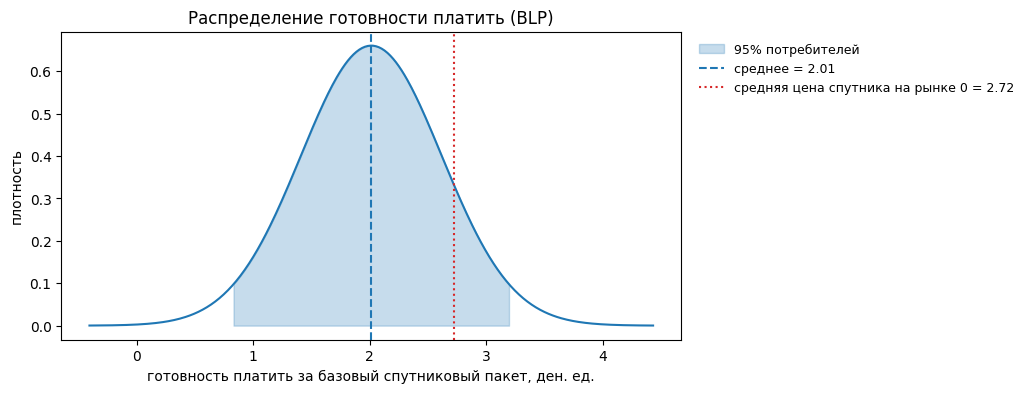

In [22]:
wtp_mean = mb[1] / alpha_mx
wtp_sd = sig[0] / alpha_mx
z = norm.ppf(0.975)
wtp_l, wtp_h = wtp_mean - z * wtp_sd, wtp_mean + z * wtp_sd
print(f'средняя WTP = {wtp_mean:.4f}, ст. отклонение = {wtp_sd:.4f}')
print(f'95% потребителей: WTP от {wtp_l:.4f} до {wtp_h:.4f}')

grid = np.linspace(wtp_mean - 4 * wtp_sd, wtp_mean + 4 * wtp_sd, 400)
dens = norm.pdf(grid, wtp_mean, wtp_sd)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, dens, color='tab:blue')
mask = (grid >= wtp_l) & (grid <= wtp_h)
ax.fill_between(grid[mask], dens[mask], alpha=0.25, color='tab:blue', label='95% потребителей')
ax.axvline(wtp_mean, color='tab:blue', ls='--', label=f'среднее = {wtp_mean:.2f}')
ax.axvline(p_sat_avg, color='tab:red', ls=':', label=f'средняя цена спутника на рынке 0 = {p_sat_avg:.2f}')
ax.set_xlabel('готовность платить за базовый спутниковый пакет, ден. ед.')
ax.set_ylabel('плотность')
ax.set_title('Распределение готовности платить (BLP)')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

Средняя готовность платить за базовый спутниковый пакет - **2.01** ден. ед., у 95% потребителей она лежит в интервале **от 0.83 до 3.20**. Это готовность платить за пакет с качеством $x=0$ без учёта $\xi$ и индивидуального шока $\varepsilon$, поэтому её нельзя напрямую сравнивать с ценой и считать по ней долю покупателей. Цена на графике показана только для масштаба.

### 4.3 Эластичности и diversion ratios в BLP

**Diversion ratio** $D_{jk}$ - доля клиентов, ушедших от пакета $j$ при росте его цены, которые переключились на пакет $k$:

$$D_{jk} = -\frac{\partial s_k/\partial p_j}{\partial s_j/\partial p_j}.$$

Это главный показатель в анализе слияний: чем больше клиентов уходят к будущему партнёру по слиянию, тем выгоднее после слияния поднимать цену (Farrell, Shapiro, 2010). В логите $D_{jk} = s_k/(1-s_j)$ - замещение пропорционально долям и не зависит от того, насколько пакеты похожи.

В матрицах PyBLP строка - пакет, который подорожал, столбец - куда ушли его клиенты, на диагонали - доля ушедших во внешнюю альтернативу.

In [23]:
E_blp = mixed_results.compute_elasticities(market_id=0)
matrix_frame(E_blp)

,p 1 (спутник),p 2 (спутник),p 3 (кабель),p 4 (кабель)
s 1 (спутник),-2.695,1.514,0.154,0.625
s 2 (спутник),2.803,-4.351,0.154,0.625
s 3 (кабель),2.039,1.101,-4.746,1.200
s 4 (кабель),2.039,1.101,0.296,-3.640


In [24]:
D_logit = logit_results.compute_diversion_ratios(market_id=0)
D_nl = nl_results.compute_diversion_ratios(market_id=0)
D_blp = mixed_results.compute_diversion_ratios(market_id=0)

# проверка логита по формуле s_k / (1 - s_j): уход от пакета 1 к пакету 2
s_m0 = m0['shares'].values
print(f'D_12 в логите: {D_logit[0, 1]:.4f}; s_2 / (1 - s_1) = {s_m0[1] / (1 - s_m0[0]):.4f}')

matrix_frame(D_blp, row_prefix='от', col_prefix='к')

D_12 в логите: 0.4481; s_2 / (1 - s_1) = 0.4481


,к 1 (спутник),к 2 (спутник),к 3 (кабель),к 4 (кабель)
от 1 (спутник),0.147,0.527,0.062,0.264
от 2 (спутник),0.687,0.097,0.041,0.174
от 3 (кабель),0.394,0.199,0.143,0.263
от 4 (кабель),0.493,0.250,0.078,0.179


### 4.4 Сравнение трёх моделей

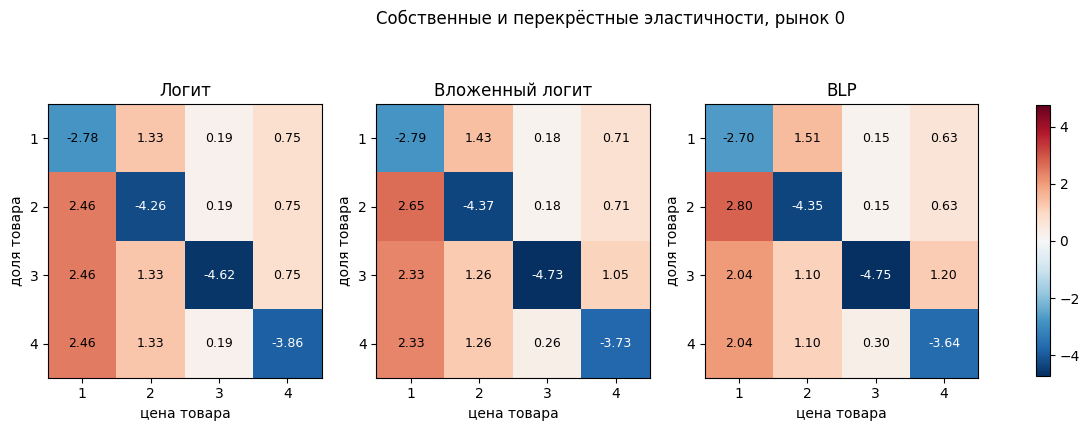

In [25]:
plot_matrices([E_logit, E_nl, E_blp], MODEL_NAMES, 'Собственные и перекрёстные эластичности, рынок 0')

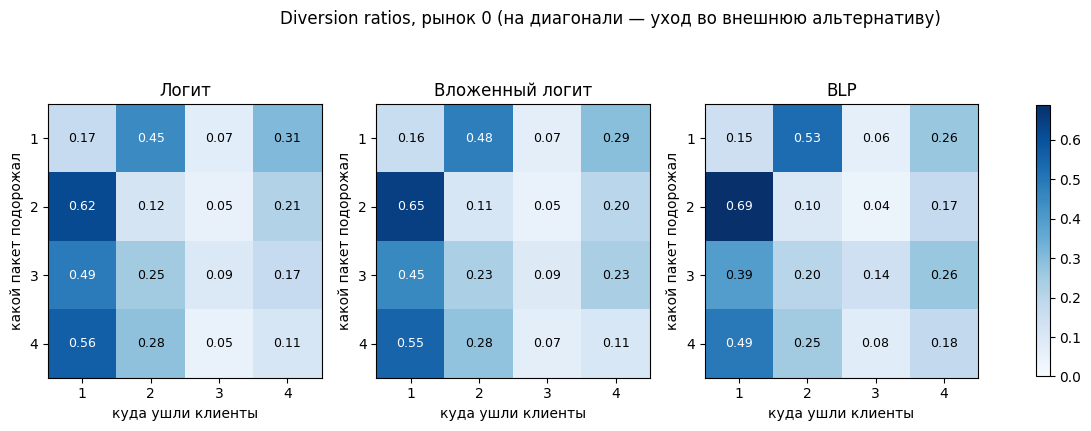

In [ ]:
plot_matrices([D_logit, D_nl, D_blp], MODEL_NAMES,
              'Diversion ratios, рынок 0 (на диагонали - уход во внешнюю альтернативу)',
              cmap='Blues', center=False, xlabel='куда ушли клиенты', ylabel='какой пакет подорожал')

In [27]:
# средние по всем рынкам diversion ratios внутри спутникового сегмента и во внешнюю альтернативу
rows = []
for name, res in zip(MODEL_NAMES, [logit_results, nl_results, mixed_results]):
    D_all = res.compute_diversion_ratios().reshape(-1, 4, 4) # рынок x пакет x пакет
    rows.append({'модель': name,
                 'от 1 к 2': D_all[:, 0, 1].mean(),
                 'от 2 к 1': D_all[:, 1, 0].mean(),
                 'от 1 во внешнюю': D_all[:, 0, 0].mean(),
                 'от 3 к 4': D_all[:, 2, 3].mean()})
pd.DataFrame(rows).set_index('модель').round(3)

,от 1 к 2,от 2 к 1,от 1 во внешнюю,от 3 к 4
модель,,,,
Логит,0.268,0.271,0.436,0.130
Вложенный логит,0.305,0.308,0.414,0.170
BLP,0.366,0.369,0.377,0.153


В логите столбцы матрицы эластичностей постоянны, а diversion ratios просто повторяют доли. Во вложенном логите замещение внутри гнезда немного сильнее. В BLP разница заметная: при подорожании спутникового пакета 1 к пакету 2 уходит больше клиентов, чем предсказывает логит, а во внешнюю альтернативу - меньше. Те, кто сильно ценит спутник, остаются в спутниковом сегменте.

Именно это важно для следующего раздела: если сливаются два близких субститута, эффект слияния зависит от того, сколько клиентов переходит между ними, а логит это недооценивает.

## 5. Сторона предложения: предельные издержки и наценки

Издержки операторов не наблюдаются, но их можно восстановить из оптимального поведения фирм (Aguirregabiria, гл. 4.3; Berry, Levinsohn, Pakes, 1995). Предположим, что фирмы конкурируют ценами по Бертрану–Нэшу и предельные издержки постоянны. Фирма $f$ выбирает цены своих пакетов, условие первого порядка для пакета $j$:

$$s_j + \sum_{k \in \mathcal{J}_f} (p_k - mc_k)\,\frac{\partial s_k}{\partial p_j} = 0.$$

В векторном виде $s + (\Omega \odot \Delta)(p - mc) = 0$, где $\Delta$ - матрица производных долей по ценам, $\Omega$ - матрица собственности ($\Omega_{jk} = 1$, если $j$ и $k$ продаёт одна фирма). Отсюда

$$mc = p + (\Omega \odot \Delta)^{-1} s.$$

Спрос уже оценён, значит, $\Delta$ известна, и издержки восстанавливаются без дополнительных оценок. Здесь каждая фирма продаёт один пакет, и в логите формула упрощается до $p_j - mc_j = \frac{1}{\alpha(1-s_j)}$.

In [ ]:
results_by_model = dict(zip(MODEL_NAMES, [logit_results, nl_results, mixed_results]))
prices = data['prices'].values
costs = {name: res.compute_costs() for name, res in results_by_model.items()}
margins = {name: prices - costs[name].ravel() for name in MODEL_NAMES} # p - mc
lerner = {name: res.compute_markups(costs=costs[name]).ravel()# PyBLP возвращает (p - mc) / p
          for name, res in results_by_model.items()}

summary = pd.DataFrame({
    name: {'mc, среднее': costs[name].mean(),
           'mc, минимум': costs[name].min(),
           'наценка p - mc, среднее': margins[name].mean(),
           'индекс Лернера (p - mc)/p, среднее': lerner[name].mean(),
           'корреляция mc со сдвигателем издержек': np.corrcoef(costs[name].ravel(),data['demand_instruments0'])[0, 1]}
    for name in MODEL_NAMES})
summary.round(3)

,Логит,Вложенный логит,BLP
"mc, среднее",2.072,2.070,2.060
"mc, минимум",1.170,1.162,1.116
"наценка p - mc, среднее",0.622,0.624,0.634
"индекс Лернера (p - mc)/p, среднее",0.235,0.237,0.240
корреляция mc со сдвигателем издержек,0.736,0.739,0.743


In [29]:
# проверка 1: у однопродуктовой фирмы индекс Лернера = 1 / |собственная эластичность|
own_el = {'Логит': E_logit, 'Вложенный логит': E_nl, 'BLP': E_blp}
for name in MODEL_NAMES:
    lerner_m0 = lerner[name][data['market_ids'] == 0]
    print(f'{name}: Лернер = 1/|эластичность| на рынке 0 —',
          np.allclose(lerner_m0, 1 / np.abs(np.diag(own_el[name]))))

# проверка 2: в логите наценка однопродуктовой фирмы равна 1 / (alpha * (1 - s))
logit_margin_formula = 1 / (alpha_iv * (1 - data['shares'].values))
print('логит: p - mc = 1 / (alpha (1 - s)) —', np.allclose(margins['Логит'], logit_margin_formula))

Логит: Лернер = 1/|эластичность| на рынке 0 — True
Вложенный логит: Лернер = 1/|эластичность| на рынке 0 — True
BLP: Лернер = 1/|эластичность| на рынке 0 — True
логит: p - mc = 1 / (alpha (1 - s)) — True


Все восстановленные предельные издержки положительны. Средняя наценка около 0.62 ден. ед. при средней цене около 2.7, средний индекс Лернера около 24%. У однопродуктовой фирмы индекс Лернера равен обратной собственной эластичности, $\frac{p_j - mc_j}{p_j} = \frac{1}{|\varepsilon_{jj}|}$, и обе проверки выше это подтверждают. Модели дают близкие наценки, потому что близки их оценки $\alpha$ и собственные эластичности; различаются они в основном перекрёстными эффектами.

Корреляция издержек со сдвигателем издержек около **0.74**. Это хорошая проверка модели: сдвигатель использовался только как инструмент в спросе, а издержки получены из условий равновесия, никак не опираясь на него. Если бы модель спроса или предположение о Бертране были сильно неверны, такой связи не было бы.

## 6. Симуляция слияния спутниковых операторов 1 и 2

После слияния одна фирма назначает цены обоих спутниковых пакетов. В условиях первого порядка меняется только матрица собственности $\Omega$: теперь $\Omega_{12} = \Omega_{21} = 1$. Фирма учитывает, что при повышении цены пакета 1 часть клиентов уйдёт к пакету 2 и останется внутри неё. Поэтому ей выгодно поднять обе цены, тем сильнее, чем больше diversion ratio между пакетами и наценка партнёра.

Схема расчёта (Nevo, 2000):
1. издержки фиксированы на уровне, восстановленном в разделе 5;
2. новые цены - решение системы условий первого порядка с новой $\Omega$ на каждом рынке;
3. по новым ценам считаем доли, излишек потребителей и прибыли.

Излишек потребителей при линейной по цене полезности (без эффекта дохода) считается по формуле логсуммы: в логите $CS_t = \frac{1}{\alpha}\ln\big(1+\sum_j e^{\delta_{jt}}\big)$, в BLP то же самое усредняется по потребителям. Излишек и прибыли - на одного потенциального потребителя рынка.

Перед симуляцией посмотрим на простой индикатор давления на цены - GUPPI (Farrell, Shapiro, 2010): $GUPPI_1 = D_{12}\cdot\frac{p_2 - mc_2}{p_1}$. Это доля цены пакета 1, которую фирма «теряет» на пакете 2, если не учитывает слияние.

In [31]:
guppi = {}
for name, res in results_by_model.items():
    D_all = res.compute_diversion_ratios().reshape(-1, 4, 4)
    p = prices.reshape(-1, 4)
    margin = margins[name].reshape(-1, 4)
    guppi[name] = (D_all[:, 0, 1] * margin[:, 1] / p[:, 0]).mean()
pd.Series(guppi, name='GUPPI пакета 1, среднее по рынкам').round(4)

Логит              0.0739
Вложенный логит    0.0837
BLP                0.1055
Name: GUPPI пакета 1, среднее по рынкам, dtype: float64

In [32]:
merged_firm_ids = data['firm_ids'].replace({2: 1}).values   # фирма 2 становится частью фирмы 1

merger = {}
for name, res in results_by_model.items():
    c = costs[name]
    new_prices = res.compute_prices(firm_ids=merged_firm_ids, costs=c)
    new_shares = res.compute_shares(new_prices)

    cs_before = res.compute_consumer_surpluses()
    cs_after = res.compute_consumer_surpluses(prices=new_prices)
    profit_before = res.compute_profits(costs=c)
    profit_after = res.compute_profits(prices=new_prices, shares=new_shares, costs=c)

    out = pd.DataFrame({'product_ids': data['product_ids'],
                        'market_ids': data['market_ids'],
                        'dp, %': (new_prices.ravel() / prices - 1) * 100,
                        'dprofit': (profit_after - profit_before).ravel()})
    s0_before = 1 - data.groupby('market_ids')['shares'].sum()
    s0_after = 1 - pd.Series(new_shares.ravel()).groupby(data['market_ids']).sum()
    merger[name] = {
        'цена пакета 1, %': out.loc[out.product_ids == 1, 'dp, %'].mean(),
        'цена пакета 2, %': out.loc[out.product_ids == 2, 'dp, %'].mean(),
        'цена пакета 3, %': out.loc[out.product_ids == 3, 'dp, %'].mean(),
        'цена пакета 4, %': out.loc[out.product_ids == 4, 'dp, %'].mean(),
        'доля внешней альтернативы, п.п.': (s0_after - s0_before).mean() * 100,
        'излишек потребителей, изменение': (cs_after - cs_before).mean(),
        'излишек потребителей, %': ((cs_after - cs_before) / cs_before).mean() * 100,
        'прибыль слившейся фирмы, изменение': out.loc[out.product_ids <= 2].groupby('market_ids')['dprofit'].sum().mean(),
        'прибыль конкурентов, изменение': out.loc[out.product_ids >= 3].groupby('market_ids')['dprofit'].sum().mean(),
    }
merger = pd.DataFrame(merger)
merger.loc['общее благосостояние, изменение'] = (merger.loc['излишек потребителей, изменение'] + merger.loc['прибыль слившейся фирмы, изменение'] 
                                                 + merger.loc['прибыль конкурентов, изменение'])
merger.round(4)

,Логит,Вложенный логит,BLP
"цена пакета 1, %",6.5101,7.7824,10.6953
"цена пакета 2, %",6.6144,7.8957,10.8308
"цена пакета 3, %",0.2622,0.3001,0.2838
"цена пакета 4, %",0.2432,0.2787,0.2641
"доля внешней альтернативы, п.п.",3.5941,4.0906,4.9084
"излишек потребителей, изменение",-0.0585,-0.0692,-0.0933
"излишек потребителей, %",-9.5114,-10.7455,-14.0890
"прибыль слившейся фирмы, изменение",0.0149,0.0186,0.0276
"прибыль конкурентов, изменение",0.0126,0.0149,0.0175
"общее благосостояние, изменение",-0.0311,-0.0356,-0.0482


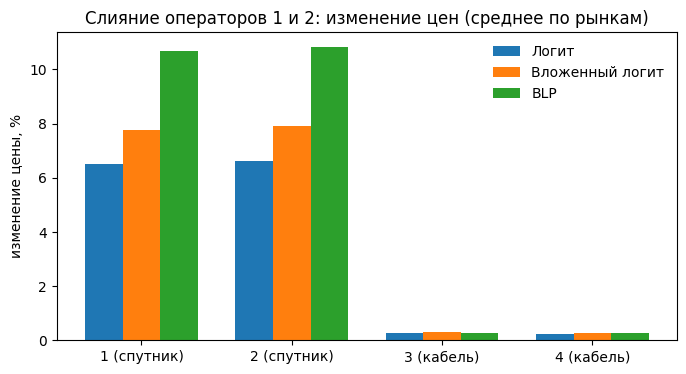

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.25
x = np.arange(4)
for i, name in enumerate(MODEL_NAMES):
    vals = merger.loc[[f'цена пакета {k}, %' for k in range(1, 5)], name].values
    ax.bar(x + (i - 1) * width, vals, width, label=name)
ax.set_xticks(x, LABELS)
ax.set_ylabel('изменение цены, %')
ax.set_title('Слияние операторов 1 и 2: изменение цен (среднее по рынкам)')
ax.legend(frameon=False)
plt.show()

**Цены.** Сливающиеся пакеты дорожают на 6.5% в логите, на 7.8% во вложенном логите и на 10.7% в BLP. Порядок совпадает с порядком diversion ratios и GUPPI (7.4%, 8.4% и 10.6%): чем больше клиентов переходит между пакетами 1 и 2, тем сильнее растут цены. GUPPI считается по данным до слияния за пару строк, а даёт уже близкий к симуляции порядок величин, поэтому его используют как быстрый первичный фильтр. Логит недооценивает эффект слияния примерно на треть, потому что занижает замещение между близкими пакетами. Кабельные операторы тоже немного поднимают цены (около 0.3%): к ним уходит часть клиентов, и им выгодно этим воспользоваться.

**Благосостояние.** Излишек потребителей падает на 9.5–14% в зависимости от модели. Прибыли растут и у слившейся фирмы, и у конкурентов, но не компенсируют потерю потребителей, общее благосостояние снижается. Часть потребителей уходит во внешнюю альтернативу.

**Что это значит.** Без снижения издержек такое слияние вредно для потребителей. Для антимонопольного анализа следующий шаг — посчитать, какое снижение предельных издержек сливающихся пакетов нужно, чтобы цены не выросли (compensating marginal cost reduction, Werden, 1996).

**Ограничения.** Модель статическая: после слияния фирмы не меняют набор и характеристики пакетов (Aguirregabiria, гл. 6, о репозиционировании), а поведение остаётся бертрановским, без координации. Издержки постоянны и не зависят от объёма.

## 7. Вход нового спутникового пакета: краткосрочный и долгосрочный эффекты

На каждый рынок добавляется новый спутниковый пакет Y от новой фирмы. Его качество и предельные издержки равны средним по спутниковым пакетам этого рынка, $\xi_Y = 0$, стартовая цена - средняя цена спутника на рынке. Рассматриваем два горизонта:
- **краткосрочный:** цены всех пакетов фиксированы, меняются только доли;
- **долгосрочный:** все фирмы, включая новую, заново выбирают цены, рынок приходит к новому равновесию Бертрана–Нэша.

Для расчёта используется `pyblp.Simulation` с оценёнными параметрами каждой модели. Для BLP берутся те же случайные потребители, что и при оценке. Перед этим проверяем, что симуляция без нового пакета воспроизводит данные: при наблюдаемых ценах доли должны совпасть с фактическими, а равновесные цены - с наблюдаемыми.

In [37]:
def build_entry_data(res, model_costs, with_entrant=True):
    '''Данные о пакетах с восстановленными издержками и xi; при необходимости добавляем пакет Y.'''
    d = data[['market_ids', 'firm_ids', 'product_ids', 'quality', 'satellite', 'wired', 'prices']].copy()
    d['costs'] = model_costs.ravel()
    d['xi'] = res.xi.ravel()
    if with_entrant:
        sat = d[d['satellite'] == 1].groupby('market_ids')
        entrant = pd.DataFrame({'market_ids': sat.size().index, 'firm_ids': 5, 'product_ids': 5,
                                'quality': sat['quality'].mean().values, 'satellite': 1, 'wired': 0,
                                'prices': sat['prices'].mean().values,
                                'costs': sat['costs'].mean().values, 'xi': 0.0})
        d = pd.concat([d, entrant])
    return d.sort_values(['market_ids', 'product_ids']).reset_index(drop=True)


def make_simulation(name, res, d):
    '''Симуляция рынка с оценёнными параметрами модели.'''
    product_data = d.drop(columns=['costs', 'xi'])
    if name == 'BLP':
        agents = res.problem.agents   # те же случайные потребители, что при оценке
        agent_data = pd.DataFrame({'market_ids': agents.market_ids.ravel(),
                                   'weights': agents.weights.ravel(),
                                   'nodes0': agents.nodes[:, 0],
                                   'nodes1': agents.nodes[:, 1]})
        return pyblp.Simulation((X1_formulation, X2_formulation), product_data, beta=res.beta,
                                sigma=res.sigma, xi=d['xi'].values, agent_data=agent_data)
    if name == 'Вложенный логит':
        product_data['nesting_ids'] = np.where(product_data['satellite'] == 1, 'satellite', 'wired')
        return pyblp.Simulation((logit_formulation,), product_data, beta=res.beta,
                                rho=res.rho, xi=d['xi'].values)
    return pyblp.Simulation((logit_formulation,), product_data, beta=res.beta, xi=d['xi'].values)


fixed_prices = pyblp.Iteration('return') # цены не пересчитываются, только доли

# проверка: без нового пакета симуляция должна воспроизвести данные
for name, res in results_by_model.items():
    d0 = build_entry_data(res, costs[name], with_entrant=False)
    sim0 = make_simulation(name, res, d0)
    shares_check = sim0.replace_endogenous(costs=d0['costs'].values, prices=d0['prices'].values, iteration=fixed_prices).product_data.shares.ravel()
    prices_check = sim0.replace_endogenous(costs=d0['costs'].values, prices=d0['prices'].values).product_data.prices.ravel()
    print(f'{name}: макс. отклонение долей {np.abs(shares_check - data["shares"].values).max():.1e}, '
          f'цен {np.abs(prices_check - prices).max():.1e}')

Логит: макс. отклонение долей 2.2e-16, цен 8.9e-16
Вложенный логит: макс. отклонение долей 2.2e-16, цен 8.9e-16
BLP: макс. отклонение долей 5.1e-15, цен 4.4e-15


In [ ]:
entry_rows, entry_sources, entry_price_change = {}, {}, {}
old_shares = data.set_index(['market_ids', 'product_ids'])['shares']

for name, res in results_by_model.items():
    d = build_entry_data(res, costs[name])
    sim = make_simulation(name, res, d)
    short_run = sim.replace_endogenous(costs=d['costs'].values, prices=d['prices'].values, iteration=fixed_prices)
    long_run = sim.replace_endogenous(costs=d['costs'].values, prices=d['prices'].values)

    r = d[['market_ids', 'product_ids', 'prices']].copy()
    r['s_short'] = short_run.product_data.shares.ravel()
    r['s_long'] = long_run.product_data.shares.ravel()
    r['p_long'] = long_run.product_data.prices.ravel()
    r = r.set_index(['market_ids', 'product_ids'])
    r['s_old'] = old_shares.reindex(r.index).fillna(0)

    # доли в среднем по рынкам: старые пакеты, новый пакет и внешняя альтернатива
    by_product = r.groupby(level='product_ids')[['s_old', 's_short', 's_long']].mean()
    outside = {col: (1 - r.groupby(level='market_ids')[col].sum()).mean() for col in ['s_old', 's_short', 's_long']}
    entry_rows[name] = {'доля Y, кратко': by_product.loc[5, 's_short'],
                        'доля Y, долго': by_product.loc[5, 's_long'],
                        'спутник 1+2: было': by_product.loc[[1, 2], 's_old'].sum(),
                        'спутник 1+2: кратко': by_product.loc[[1, 2], 's_short'].sum(),
                        'кабель 3+4: было': by_product.loc[[3, 4], 's_old'].sum(),
                        'кабель 3+4: кратко': by_product.loc[[3, 4], 's_short'].sum(),
                        'не покупают: было': outside['s_old'],
                        'не покупают: кратко': outside['s_short']}

    # откуда пришли клиенты Y в краткосрочном периоде
    loss = (r['s_old'] - r['s_short']).groupby(level='product_ids').sum()
    outside_loss = (1 - r.groupby(level='market_ids')['s_old'].sum() - (1 - r.groupby(level='market_ids')['s_short'].sum())).sum()
    total_Y = r.xs(5, level='product_ids')['s_short'].sum()
    entry_sources[name] = {'от спутника 1+2': (loss[1] + loss[2]) / total_Y,
                           'от кабеля 3+4': (loss[3] + loss[4]) / total_Y,
                           'из внешней альтернативы': outside_loss / total_Y}

    # реакция цен в долгосрочном периоде
    entry_price_change[name] = ((r['p_long'] / r['prices'] - 1) * 100).groupby(level='product_ids').mean()

pd.DataFrame(entry_rows).round(4)

,Логит,Вложенный логит,BLP
"доля Y, кратко",0.1557,0.1537,0.1486
"доля Y, долго",0.1605,0.1597,0.1569
спутник 1+2: было,0.4287,0.4287,0.4287
спутник 1+2: кратко,0.3611,0.3564,0.3506
кабель 3+4: было,0.2341,0.2341,0.2341
кабель 3+4: кратко,0.2000,0.2027,0.2063
не покупают: было,0.3372,0.3372,0.3372
не покупают: кратко,0.2832,0.2871,0.2945


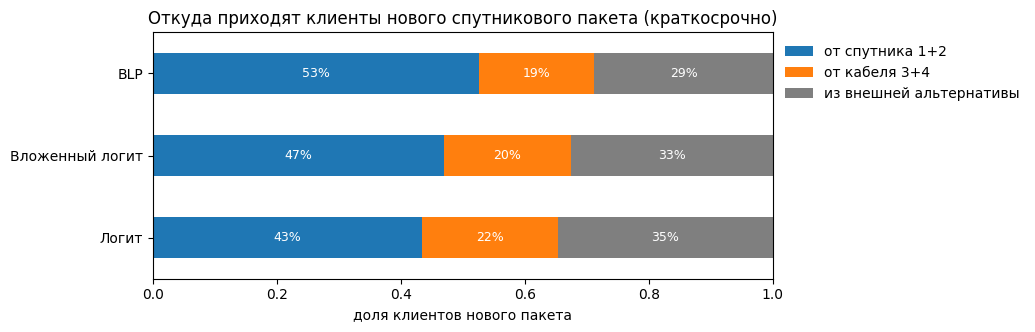

,от спутника 1+2,от кабеля 3+4,из внешней альтернативы
Логит,0.435,0.218,0.347
Вложенный логит,0.470,0.204,0.326
BLP,0.526,0.187,0.288


In [38]:
sources = pd.DataFrame(entry_sources).T
ax = sources.plot(kind='barh', stacked=True, figsize=(8, 3.2), color=['tab:blue', 'tab:orange', 'tab:gray'])
for i, name in enumerate(sources.index):
    left = 0
    for v in sources.loc[name]:
        ax.text(left + v / 2, i, f'{v:.0%}', ha='center', va='center', color='white', fontsize=9)
        left += v
ax.set_xlim(0, 1)
ax.set_xlabel('доля клиентов нового пакета')
ax.set_title('Откуда приходят клиенты нового спутникового пакета (краткосрочно)')
ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
plt.show()
sources.round(3)

In [39]:
price_change = pd.DataFrame(entry_price_change).rename(index={1: LABELS[0], 2: LABELS[1], 3: LABELS[2],
                                                              4: LABELS[3], 5: 'Y (новый, спутник)'})
price_change.round(2).rename_axis('изменение цены в долгосрочном периоде, %')

,Логит,Вложенный логит,BLP
"изменение цены в долгосрочном периоде, %",,,
1 (спутник),-1.14,-1.55,-2.30
2 (спутник),-1.13,-1.53,-2.27
3 (кабель),-0.51,-0.50,-0.39
4 (кабель),-0.50,-0.49,-0.38
"Y (новый, спутник)",-2.12,-2.61,-3.64


**Краткосрочный эффект.** В логите новый пакет забирает клиентов у всех ровно пропорционально их долям: 43% от спутниковых пакетов, 22% от кабельных, 35% у тех, кто раньше ничего не покупал. В BLP от спутниковых пакетов приходит **53%** клиентов, от кабельных и из внешней альтернативы - меньше. Потребители, которые выбрали спутник, сильно его ценят, и новый спутниковый пакет конкурирует прежде всего с ними. Вложенный логит находится между двумя моделями.

**Долгосрочный эффект.** После входа все цены снижаются: конкуренция усилилась. В BLP спутниковые операторы снижают цены сильнее (около 2.3% против 1.1% в логите), а кабельные - слабее. Это та же логика: в BLP новый пакет - близкий конкурент именно для спутника. Новый пакет тоже ставит цену ниже стартовой средней. Его доля в долгосрочном периоде немного выше краткосрочной.

**Почему это важно на практике.** Если спутниковый оператор планирует реакцию на вход конкурента по логиту, он недооценит угрозу для своего сегмента, а кабельный оператор - переоценит. Для оценки каннибализации при запуске нового продукта внутри компании логит даёт ту же ошибку.

## 8. Выводы

| | Логит (IV) | Вложенный логит | BLP |
|---|---|---|---|
| $\hat\alpha$ | 1.988 | 1.881 | 2.085 |
| Структура замещения | пропорционально долям (IIA) | сильнее внутри гнезда | зависит от разброса вкусов |
| Ключевой параметр | — | $\hat\rho = 0.09$ (незначим) | $\hat\sigma_{sat}=1.26$, $\hat\sigma_{wired}=0.13$ |
| Рост цен сливающихся пакетов | 6.5% | 7.8% | 10.7% |
| Клиенты нового пакета от спутника 1+2 | 43% | 47% | 53% |

1. Учёт эндогенности цены критичен: OLS почти вдвое занижает ценовую чувствительность, а значит, завышает рыночную власть.
2. Восстановленные из условий равновесия издержки положительны и согласуются со сдвигателем издержек - модель спроса и предположение о конкуренции по Бертрану выглядят разумно.
3. Выбор модели спроса существенно меняет ответы на прикладные вопросы. Логит, который распределяет замещение пропорционально долям, недооценивает рост цен после слияния примерно на треть и неверно показывает, у кого новый пакет забирает клиентов.
4. Гетерогенность на этом рынке — в оценке спутникового ТВ, а не в делении на «спутник» и «кабель» как таковом: вложенный логит почти не отличается от обычного, а BLP заметно отличается.

**Ограничения**
- Данные синтетические; результаты иллюстрируют только методы, а не реальный рынок.
- Конкуренция предполагается бертрановской, издержки - постоянными. Конкуренция не тестировалась против альтернатив (например, сговора, см. Aguirregabiria, гл. 4).
- Модель статическая: характеристики пакетов после слияния или входа не меняются.
- Случайные коэффициенты только у типа услуги; цена и качество ценятся всеми одинаково. Интегрирование по 100 случайным потребителям, устойчивость к числу точек не проверялась.

**Литература**
- Aguirregabiria, V. *Empirical Industrial Organization: Models, Methods, and Applications*, гл. 2 и 4.
- Berry, S. (1994). Estimating Discrete-Choice Models of Product Differentiation. *RAND Journal of Economics*.
- Berry, S., Levinsohn, J., Pakes, A. (1995). Automobile Prices in Market Equilibrium. *Econometrica*.
- Nevo, A. (2000). Mergers with Differentiated Products: The Case of the Ready-to-Eat Cereal Industry. *RAND Journal of Economics*.
- Farrell, J., Shapiro, C. (2010). Antitrust Evaluation of Horizontal Mergers: An Economic Alternative to Market Definition. *B.E. Journal of Theoretical Economics*.
- Werden, G. (1996). A Robust Test for Consumer Welfare Enhancing Mergers among Sellers of Differentiated Products. *Journal of Industrial Economics*.
- Conlon, C., Gortmaker, J. (2020). Best Practices for Differentiated Products Demand Estimation with PyBLP. *RAND Journal of Economics*.